# Evaluating classifiers – beyond accuracy

**Video 9.5** · ShopKart project

**Goal:** Use the confusion matrix, precision, recall and F1 to judge the return-prediction model properly, see why accuracy misleads with imbalanced data, and tune the decision threshold.

**How to open in Colab:** go to colab.research.google.com → File → Upload notebook → choose this file. Then click the folder icon on the left and drag these data files in: `shopkart_clean.csv`. Then run cells from top to bottom (Shift + Enter).

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("shopkart_clean.csv")

# Target (y): 1 if the order was returned, 0 if kept
y = (df["returned"] == "Y").astype(int)

# Features (X): things we KNOW at the time the order is placed or shipped
features = ["category", "city", "payment_mode", "delivery_days",
            "discount", "membership", "age", "unit_price"]
X = pd.get_dummies(df[features], drop_first=True, dtype=int)   # text columns -> 0/1 columns

# Same split as Video 9.4: 80% train, 20% test, same share of returns in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (4000, 23)  Test: (1000, 23)


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, classification_report)
import matplotlib.pyplot as plt
import numpy as np

# Same logistic regression as Video 9.4
logreg = make_pipeline(StandardScaler(), LogisticRegression())
logreg.fit(X_train, y_train)
pred = logreg.predict(X_test)
proba = logreg.predict_proba(X_test)[:, 1]

## 1. The accuracy trap
A 'dumb model' that ALWAYS says "not returned" – how accurate is it?

In [3]:
always_no = np.zeros(len(y_test), dtype=int)
print("Dumb model accuracy  :", round(accuracy_score(y_test, always_no) * 100, 1), "%")
print("Our model accuracy   :", round(accuracy_score(y_test, pred) * 100, 1), "%")
print("Returns in test set  :", y_test.sum(), "of", len(y_test))

Dumb model accuracy  : 86.3 %
Our model accuracy   : 86.1 %
Returns in test set  : 137 of 1000


Both are about 86%. **When one class is rare, accuracy hides everything.** We need to look at the returns separately.

## 2. The confusion matrix
|  | Predicted: Kept | Predicted: Returned |
|---|---|---|
| **Actually kept** | True Negative (TN) | False Positive (FP) – false alarm |
| **Actually returned** | False Negative (FN) – missed return | True Positive (TP) – caught it |

In [4]:
cm = confusion_matrix(y_test, pred)
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

[[861   2]
 [137   0]]
TN=861  FP=2  FN=137  TP=0


## 3. Precision, recall, F1
- **Precision** = TP / (TP + FP): when the model says 'return', how often is it right?
- **Recall** = TP / (TP + FN): of all real returns, how many did we catch?
- **F1** = a single score that balances precision and recall (high only when both are decent).

In [5]:
print(classification_report(y_test, pred, target_names=["Kept", "Returned"], zero_division=0))

              precision    recall  f1-score   support

        Kept       0.86      1.00      0.93       863
    Returned       0.00      0.00      0.00       137

    accuracy                           0.86      1000
   macro avg       0.43      0.50      0.46      1000
weighted avg       0.74      0.86      0.80      1000



At the default threshold of 0.5, recall for 'Returned' is **0** – the model catches none of the 137 returns. Useless for the business, even with 86% accuracy.

## 4. Threshold tuning
`predict` says 'returned' only if probability ≥ 0.5. Our model's probabilities rarely go that high. If we lower the threshold, we catch more returns (recall ↑) but raise more false alarms (precision ↓).

In [6]:
rows = []
for t in [0.5, 0.3, 0.2, 0.15]:
    p = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({"threshold": t, "flagged orders": tp + fp, "returns caught (TP)": tp,
                 "false alarms (FP)": fp,
                 "precision": round(precision_score(y_test, p, zero_division=0), 2),
                 "recall": round(recall_score(y_test, p), 2),
                 "F1": round(f1_score(y_test, p), 2),
                 "accuracy": round(accuracy_score(y_test, p), 2)})
pd.DataFrame(rows)

,threshold,flagged orders,returns caught (TP),false alarms (FP),precision,recall,F1,accuracy
0,0.50,2,0,2,0.00,0.00,0.00,0.86
1,0.30,42,17,25,0.40,0.12,0.19,0.85
2,0.20,179,47,132,0.26,0.34,0.30,0.78
3,0.15,323,71,252,0.22,0.52,0.31,0.68


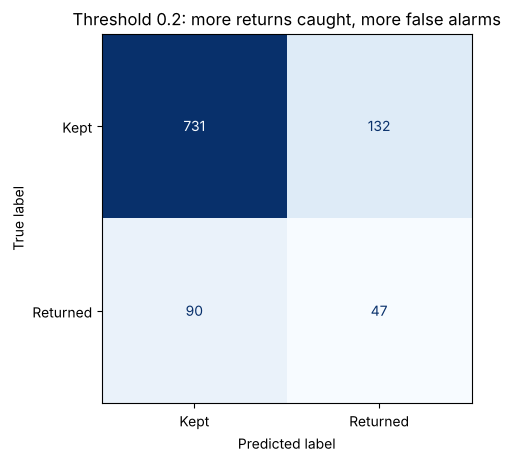

In [7]:
cm2 = confusion_matrix(y_test, (proba >= 0.2).astype(int))
ConfusionMatrixDisplay(cm2, display_labels=["Kept", "Returned"]).plot(cmap="Blues", colorbar=False)
plt.title("Threshold 0.2: more returns caught, more false alarms")
plt.show()

## Honest interpretation – which threshold?
- Notice **accuracy goes DOWN** as the model becomes more useful. Another reason not to trust accuracy alone.
- At 0.2 we flag about 18% of orders and catch about a third of returns; roughly 1 in 4 flagged orders really is returned (vs 1 in 7 at random).
- The right threshold is a **business decision**: if a confirmation call costs ₹10 and a return costs ₹200, false alarms are cheap and missed returns are expensive → choose a lower threshold (higher recall).
- The model is modest (it only uses information we have at order time). That is normal – and still better than guessing.

## Recap
- Accuracy can lie when one class is rare
- Confusion matrix: TN, FP, FN, TP
- Precision = 'when I say yes, am I right?'; Recall = 'did I catch them all?'
- Threshold is a business knob: lower → more recall, less precision

## Bonus (not shown in the video): the 0.5 confusion matrix as a picture
The same four numbers as the printed matrix above (TN 861, FP 2, FN 137, TP 0), drawn as a coloured grid. The whole bottom row is missed returns.

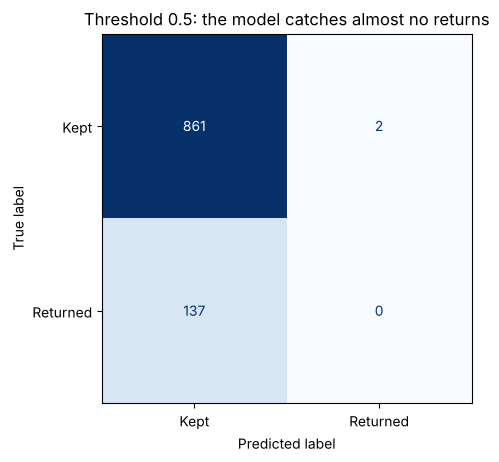

In [8]:
ConfusionMatrixDisplay(cm, display_labels=["Kept", "Returned"]).plot(cmap="Blues", colorbar=False)
plt.title("Threshold 0.5: the model catches almost no returns")
plt.show()